In [1]:
import sys
sys.path.append("..")

import os
import joblib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
from sklearn.metrics import make_scorer, classification_report, ConfusionMatrixDisplay

from mindscope.preprocessing import build_pipeline, TARGET

sns.set_style("whitegrid")

## 1. Loading the data

The models are tuned on the train set only, and the test set is used once at the end for the final evaluation.

In [2]:
X_train = pd.read_csv("../data/processed/X_train.csv")
y_train = pd.read_csv("../data/processed/y_train.csv")[TARGET]
X_test = pd.read_csv("../data/processed/X_test.csv")
y_test = pd.read_csv("../data/processed/y_test.csv")[TARGET]

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (1600, 15)
Test: (400, 15)


## 2. Selecting the most promising models

Logistic Regression > Random Forest > KNN, so I tune Logistic Regression and Random Forest and I leave KNN out.

## 3. Hyperparameter tuning

I use `GridSearchCV` with the same 5-fold stratified cross-validation and the macro F1-score for both models.

In [3]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

### 3.1 Logistic Regression

In [4]:
lr_pipeline = build_pipeline(LogisticRegression(max_iter=2000), X_train)

lr_params = {
    "model__C": [0.01, 0.1, 1, 10, 100],
    "model__solver": ["lbfgs", "newton-cg"],
}

grid_lr = GridSearchCV(lr_pipeline, lr_params, cv=cv, scoring="f1_macro", n_jobs=-1)
grid_lr.fit(X_train, y_train)

print("Best parameters:", grid_lr.best_params_)
print("Best CV F1-score:", round(grid_lr.best_score_, 3))

Best parameters: {'model__C': 10, 'model__solver': 'lbfgs'}
Best CV F1-score: 0.752


### 3.2 Random Forest

The grid is kept small so that the search stays fast.

In [5]:
rf_pipeline = build_pipeline(RandomForestClassifier(random_state=42), X_train)

rf_params = {
    "model__n_estimators": [100, 200, 300],
    "model__max_depth": [None, 10, 20],
    "model__min_samples_leaf": [1, 2, 4],
}

grid_rf = GridSearchCV(rf_pipeline, rf_params, cv=cv, scoring="f1_macro", n_jobs=-1)
grid_rf.fit(X_train, y_train)

print("Best parameters:", grid_rf.best_params_)
print("Best CV F1-score:", round(grid_rf.best_score_, 3))

Best parameters: {'model__max_depth': 20, 'model__min_samples_leaf': 2, 'model__n_estimators': 200}
Best CV F1-score: 0.69


## 4. Comparison of the models

I compare each model with its default parameters and with its tuned parameters, using the same cross-validation.

In [6]:
baseline_lr = cross_val_score(build_pipeline(LogisticRegression(max_iter=2000), X_train), X_train, y_train, cv=cv, scoring="f1_macro").mean()
baseline_rf = cross_val_score(build_pipeline(RandomForestClassifier(random_state=42), X_train), X_train, y_train, cv=cv, scoring="f1_macro").mean()

comparison = pd.DataFrame({
    "Default F1 (CV)": [baseline_lr, baseline_rf],
    "Tuned F1 (CV)": [grid_lr.best_score_, grid_rf.best_score_],
}, index=["Logistic Regression", "Random Forest"]).round(3)

comparison

,Default F1 (CV),Tuned F1 (CV)
Logistic Regression,0.752,0.752
Random Forest,0.685,0.690


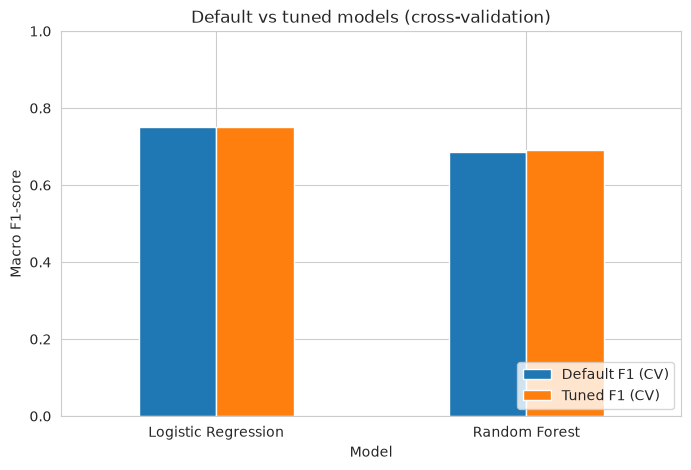

In [7]:
comparison.plot(kind="bar", figsize=(8, 5))
plt.title("Default vs tuned models (cross-validation)")
plt.xlabel("Model")
plt.ylabel("Macro F1-score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.show()

## 5. Choosing the final model for the business context

### 5.1 Recall of the High risk class

The goal is to find the students at risk, and missing a High risk student is the worst mistake, so I check the recall of the High class for each tuned model.

In [8]:
searches = {"Logistic Regression": grid_lr, "Random Forest": grid_rf}

high_recall = make_scorer(recall_score, labels=["High"], average="macro")

for name, search in searches.items():
    scores = cross_val_score(search.best_estimator_, X_train, y_train, cv=cv, scoring=high_recall)
    print(name, "- recall of the High class (CV):", round(scores.mean(), 3))

Logistic Regression - recall of the High class (CV): 0.813
Random Forest - recall of the High class (CV): 0.798


### 5.2 Final model

I keep the model with the best tuned F1-score, and I use the recall of the High class to confirm the choice.

In [9]:
best_name = comparison["Tuned F1 (CV)"].idxmax()
final_model = searches[best_name].best_estimator_

print("Final model:", best_name)
print("Parameters:", searches[best_name].best_params_)

Final model: Logistic Regression
Parameters: {'model__C': 10, 'model__solver': 'lbfgs'}


## 6. Evaluation on the independent test set

### 6.1 Metrics

In [10]:
y_pred = final_model.predict(X_test)
y_proba = final_model.predict_proba(X_test)

test_results = pd.Series({
    "Accuracy": accuracy_score(y_test, y_pred),
    "Precision": precision_score(y_test, y_pred, average="macro"),
    "Recall": recall_score(y_test, y_pred, average="macro"),
    "F1-score": f1_score(y_test, y_pred, average="macro"),
    "ROC-AUC": roc_auc_score(y_test, y_proba, multi_class="ovr", labels=final_model.classes_),
}).round(3)

print(test_results)

Accuracy     0.755
Precision    0.755
Recall       0.754
F1-score     0.755
ROC-AUC      0.914
dtype: float64


In [11]:
print(classification_report(y_test, y_pred, labels=["Low", "Medium", "High"]))

              precision    recall  f1-score   support

         Low       0.82      0.80      0.81       132
      Medium       0.63      0.64      0.63       132
        High       0.81      0.82      0.82       136

    accuracy                           0.76       400
   macro avg       0.75      0.75      0.75       400
weighted avg       0.76      0.76      0.76       400



### 6.2 Confusion matrix

<Figure size 600x500 with 0 Axes>

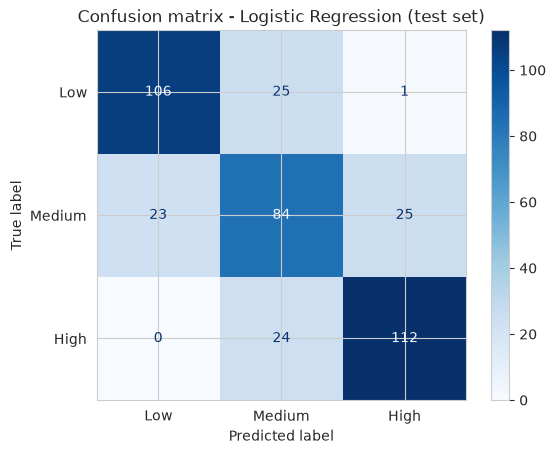

In [12]:
labels = ["Low", "Medium", "High"]

plt.figure(figsize=(6, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred, labels=labels, cmap="Blues")
plt.title("Confusion matrix - " + best_name + " (test set)")
plt.show()

## 7. Error analysis and limits

### 7.1 Which errors does the model make

In [13]:
errors = (y_pred != y_test)

print("Number of errors:", errors.sum(), "out of", len(y_test))
print()
print("Error rate by true class (%)")
print((errors.groupby(y_test).mean() * 100).round(1))

Number of errors: 98 out of 400

Error rate by true class (%)
Mental_Health_Risk
High      17.6
Low       19.7
Medium    36.4
Name: Mental_Health_Risk, dtype: float64


In [14]:
pairs = pd.DataFrame({"True": y_test, "Predicted": y_pred})[errors]
pairs.value_counts()

True    Predicted
Low     Medium       25
Medium  High         25
High    Medium       24
Medium  Low          23
Low     High          1
Name: count, dtype: int64

### 7.2 Who are the misclassified students

In [15]:
num_cols = X_test.select_dtypes(include="number").columns.tolist()

profile = X_test.assign(Misclassified=errors.values).groupby("Misclassified")[num_cols].mean().T.round(2)
profile

Misclassified,False,True
Age,21.07,21.24
Year_of_Study,2.66,2.71
Sleep_Hours,6.80,6.76
Study_Hours_Per_Week,20.21,19.70
GPA,2.56,2.55
Social_Media_Hours,5.87,6.12
Screen_Time_Hours,8.34,8.72
Financial_Stress,5.96,5.84
Family_Support,6.55,6.32
Attendance_Rate,85.01,85.88


### 7.3 Limits of the model

- This is an educational prototype, not a diagnostic or screening tool.
- The test set is small (400 students), so the results can change with another split.
- Most common confusions: almost all errors involve the Medium class (97 of 98). Low and High are almost never confused with each other.
- Other limits: Medium is the hardest class (36.4% error rate), and the misclassified students have no clear profile.

## 8. Summary and justification of the choice

- Final model: Logistic Regression
- Best parameters: C = 10, solver = lbfgs
- Test results: accuracy 0.755 / F1-score 0.755 / ROC-AUC 0.914
- Why this model:
  - Best F1-score in cross-validation.
  - Best recall for the High class.
  - Stable: the F1-score is almost the same in cross-validation and on the test set.

## 9. Saving the pipeline

In [16]:
os.makedirs("../models", exist_ok=True)
joblib.dump(final_model, "../models/best_pipeline.joblib")

loaded_model = joblib.load("../models/best_pipeline.joblib")
print(loaded_model.predict(X_test.head()))
print(y_test.head().tolist())

['High' 'Medium' 'Medium' 'High' 'High']
['High', 'Medium', 'Low', 'Medium', 'High']
